# Proyecto Cata Digital — Celler del Túria
**UD2 · Programación en Inteligencia Artificial · IES Abastos**

## Objetivo
Predecir si un vino tinto merece la etiqueta **Selección** (nota sensorial ≥ 7) a partir de sus 11 medidas fisicoquímicas. Se comparan una neurona M-P simplificada, un perceptrón y un perceptrón multicapa.

**Criterio de negocio:** el falso positivo (vino mediocre etiquetado como Selección) es más costoso que el falso negativo. Por eso no se debe elegir el modelo solo por su porcentaje global de aciertos.

> Ejecuta todas las celdas de arriba abajo. El CSV se descarga automáticamente; si falla, puedes subir `winequality-red.csv` cuando Colab lo solicite.

## 1. Preparación y carga de datos
El conjunto contiene 1.599 vinos, 11 variables de laboratorio y la nota del panel de cata. El archivo está separado por punto y coma.

In [1]:
import os, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score, ConfusionMatrixDisplay)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "winequality-red.csv"
if not os.path.exists(DATA_PATH):
    url = "https://raw.githubusercontent.com/CUNY-CISC-3225/datasets/main/wine_quality/winequality-red.csv"
    try:
        urllib.request.urlretrieve(url, DATA_PATH)
    except Exception:
        try:
            from google.colab import files
            print("No se pudo descargar automáticamente. Sube winequality-red.csv.")
            uploaded = files.upload()
            DATA_PATH = next(iter(uploaded))
        except Exception as e:
            raise RuntimeError("Coloca winequality-red.csv en la carpeta del notebook.") from e

df = pd.read_csv(DATA_PATH, sep=";")
print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Análisis exploratorio
La variable objetivo se crea con el criterio indicado por el cliente: nota ≥ 7 equivale a Selección. Primero revisamos tipos, ausencias, duplicados y distribución de clases.

In [2]:
df.info()
print("\\nValores ausentes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

df["seleccion"] = (df["quality"] >= 7).astype(int)
print("\\nDistribución de calidad:")
display(df["quality"].value_counts().sort_index())
print("\\nDistribución de clases (0=Normal, 1=Selección):")
display(df["seleccion"].value_counts().rename(index={0:"Normal",1:"Selección"}))
print("Porcentaje Selección:", round(df["seleccion"].mean()*100, 2), "%")

<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB
\nValores ausentes: 0
Filas duplicadas: 240
\nDistribución de calidad:


quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

\nDistribución de clases (0=Normal, 1=Selección):


seleccion
Normal       1382
Selección     217
Name: count, dtype: int64

Porcentaje Selección: 13.57 %


In [5]:
# Comparación de medias por clase: orienta el análisis, no demuestra causalidad.

df["seleccion"] = df["seleccion"].astype(int)

features = [c for c in df.columns if c not in ["quality", "seleccion"]]

medias = df.groupby("seleccion")[features].mean()

if 0 not in medias.index or 1 not in medias.index:
    raise ValueError("No se encuentran las dos clases: Normal (0) y Selección (1).")

display(medias.T.rename(columns={0: "Normal", 1: "Selección"}))

diferencias = (medias.loc[1] - medias.loc[0]).sort_values(
    key=lambda x: x.abs(),
    ascending=False
)

print("Variables con mayor diferencia absoluta de medias:")
display(diferencias.to_frame("Diferencia (Selección - Normal)"))

seleccion,Normal,Selección
fixed acidity,8.236831,8.847005
volatile acidity,0.547022,0.405530
citric acid,0.254407,0.376498
residual sugar,2.512120,2.708756
chlorides,0.089281,0.075912
free sulfur dioxide,16.172214,13.981567
total sulfur dioxide,48.285818,34.889401
density,0.996859,0.996030
pH,3.314616,3.288802
sulphates,0.644754,0.743456


Variables con mayor diferencia absoluta de medias:


,Diferencia (Selección - Normal)
total sulfur dioxide,-13.396417
free sulfur dioxide,-2.190647
alcohol,1.267012
fixed acidity,0.610174
residual sugar,0.196636
volatile acidity,-0.141492
citric acid,0.122091
sulphates,0.098702
pH,-0.025815
chlorides,-0.013368


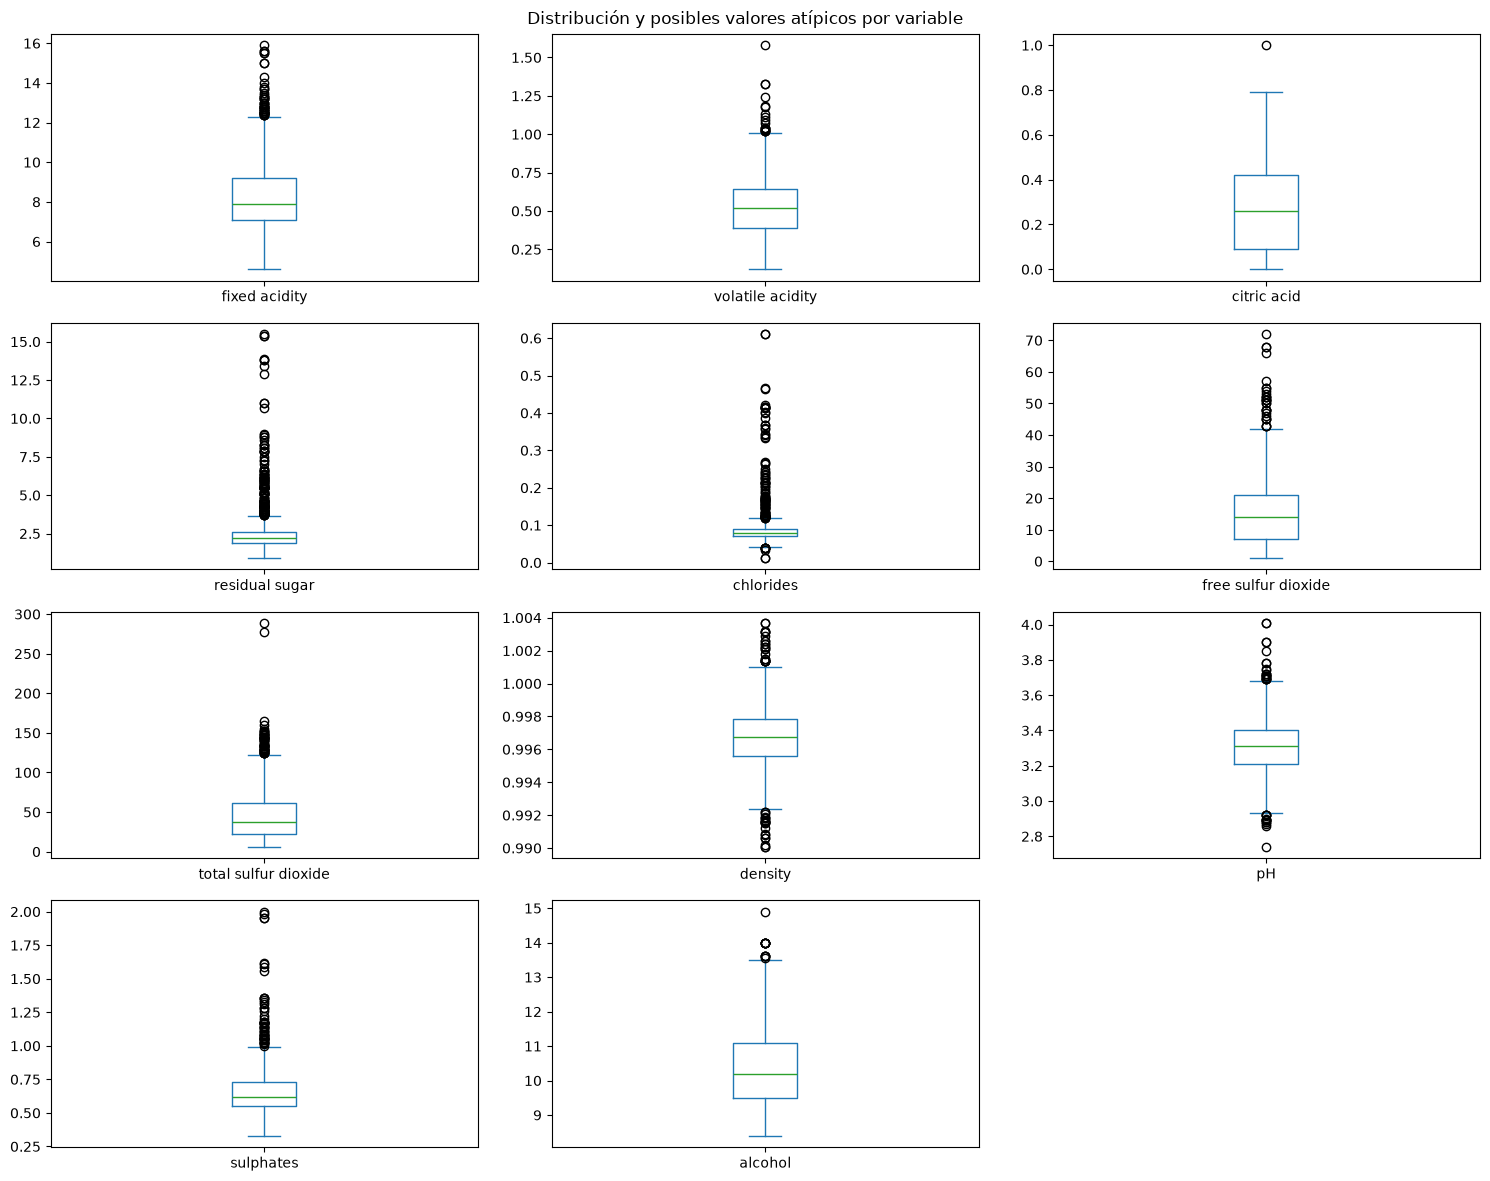

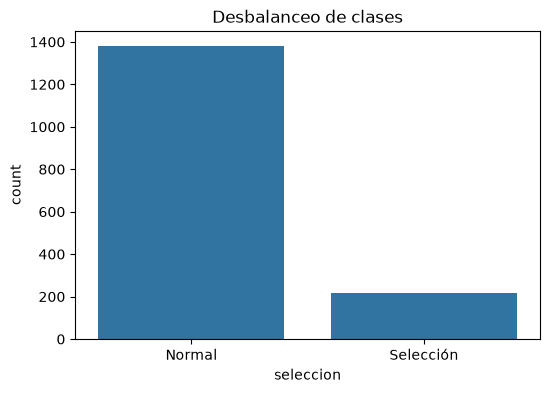

In [6]:
# Diagramas de caja para detectar posibles valores atípicos.
df[features].plot(kind="box", subplots=True, layout=(4,3), figsize=(15,12), sharex=False)
plt.suptitle("Distribución y posibles valores atípicos por variable")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(data=df, x="seleccion")
plt.xticks([0,1], ["Normal","Selección"])
plt.title("Desbalanceo de clases")
plt.show()

### Conclusiones del análisis
- La clase Selección es minoritaria; por tanto, la exactitud global puede resultar engañosa.
- Los diagramas de caja permiten localizar valores extremos, pero no se eliminan automáticamente: podrían ser vinos reales.
- Las diferencias entre medias ayudan a formular hipótesis sobre las variables relevantes.
- La división estratificada conserva aproximadamente la proporción de ambas clases.

## 3. Preparación común de entrenamiento y prueba
Separamos el 80 % para entrenar y el 20 % para probar. Los tres modelos utilizarán exactamente las mismas filas. Los puntos de corte y el escalado se calculan únicamente con entrenamiento.

In [7]:
X = df[features].copy()
y = df["seleccion"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Entrenamiento:", X_train.shape, "Prueba:", X_test.shape)
print("Proporción Selección train:", round(y_train.mean()*100,2), "%")
print("Proporción Selección test:", round(y_test.mean()*100,2), "%")

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Entrenamiento: (1279, 11) Prueba: (320, 11)
Proporción Selección train: 13.6 %
Proporción Selección test: 13.44 %


## 4. Modelo 1 — Neurona M-P (1943)
La neurona M-P original recibe entradas binarias. Para adaptar las 11 medidas, cada variable se convierte en 0 o 1 usando la **mediana del conjunto de entrenamiento** como punto de corte. Se pierde la distancia exacta entre valores: por ejemplo, dos vinos por encima de la mediana reciben ambos un 1.

Para construir una regla interpretable, se asigna a cada entrada binaria un peso según la diferencia de medias observada en entrenamiento. La suma ponderada se compara con un umbral. El umbral se ajusta en entrenamiento para penalizar más los falsos positivos. Es una **adaptación didáctica de neurona de umbral**, no una reproducción histórica exacta del modelo original.

In [8]:
# Binarización: cortes aprendidos SOLO con entrenamiento.
medianas = X_train.median()
Xtr_bin = (X_train > medianas).astype(int)
Xte_bin = (X_test > medianas).astype(int)

# Dirección e intensidad de la asociación calculadas SOLO en entrenamiento.
medias_train = X_train.assign(target=y_train).groupby("target")[features].mean()
pesos = (medias_train.loc[1] - medias_train.loc[0]).values
# Normalizamos para que las magnitudes sean comparables.
pesos = pesos / (np.sum(np.abs(pesos)) + 1e-12)

score_train = Xtr_bin.values @ pesos
score_test = Xte_bin.values @ pesos

# Elegimos el umbral en entrenamiento minimizando el coste orientativo:
# FP = 2.500 € y FN = 1.200 € por lote.
def elegir_umbral(scores, y_real, coste_fp=2500, coste_fn=1200):
    candidatos = np.unique(scores)
    mejor = None
    for t in candidatos:
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0,1]).ravel()
        coste = fp*coste_fp + fn*coste_fn
        if mejor is None or coste < mejor[0]:
            mejor = (coste, t)
    return mejor[1]

umbral_mp = elegir_umbral(score_train, y_train.to_numpy())
y_pred_mp = (score_test >= umbral_mp).astype(int)
print("Medianas usadas como cortes:")
display(medianas.to_frame("Corte"))
print("Pesos de la regla:")
display(pd.Series(pesos, index=features).sort_values(key=abs, ascending=False).to_frame("Peso"))
print("Umbral elegido en entrenamiento:", umbral_mp)

Medianas usadas como cortes:


,Corte
fixed acidity,7.9000
volatile acidity,0.5200
citric acid,0.2600
residual sugar,2.2000
chlorides,0.0790
free sulfur dioxide,13.0000
total sulfur dioxide,38.0000
density,0.9968
pH,3.3100
sulphates,0.6200


Pesos de la regla:


,Peso
total sulfur dioxide,-0.763017
free sulfur dioxide,-0.117014
alcohol,0.063657
fixed acidity,0.028258
residual sugar,0.008920
volatile acidity,-0.006807
citric acid,0.005850
sulphates,0.004569
pH,-0.001238
chlorides,-0.000628


Umbral elegido en entrenamiento: 0.11125458350078363


### Interpretación del modelo M-P
La binarización simplifica los datos y facilita una regla explicable, pero elimina información: no distingue cuánto supera una medida su mediana. La regla debe evaluarse por falsos positivos y falsos negativos, no solo por aciertos.

## 5. Modelo 2 — Perceptrón (1958)
El perceptrón utiliza las medidas numéricas escaladas. El escalador se ajustó solo con entrenamiento. Los coeficientes permiten observar qué variables tienen mayor peso dentro de este modelo lineal; su signo depende de la codificación y del escalado.

In [9]:
modelo_perceptron = Perceptron(
    max_iter=2000, tol=1e-4, random_state=RANDOM_STATE,
    class_weight="balanced"
)
modelo_perceptron.fit(X_train_scaled, y_train)
y_pred_perc = modelo_perceptron.predict(X_test_scaled)

coef = pd.Series(modelo_perceptron.coef_[0], index=features)
display(coef.reindex(coef.abs().sort_values(ascending=False).index).to_frame("Coeficiente"))

,Coeficiente
volatile acidity,-8.158210
total sulfur dioxide,-6.074881
fixed acidity,5.194767
chlorides,-4.692474
alcohol,3.718307
pH,-3.664290
citric acid,3.586249
sulphates,1.266750
density,-1.239206
free sulfur dioxide,-0.588417


## 6. Modelo 3 — Perceptrón multicapa (MLP)
Probamos varias arquitecturas con el mismo conjunto de entrenamiento. Se utiliza regularización L2 (`alpha`) y parada temprana (`early_stopping`) para reducir el sobreajuste. La selección de arquitectura se hace con una partición interna de entrenamiento; el test final queda reservado para la comparación.

In [10]:
arquitecturas = [(16,), (32,16), (64,32)]
resultados_validacion = []
modelos_mlp = {}

# Validación interna a partir SOLO del entrenamiento.
X_sub, X_val, y_sub, y_val = train_test_split(
    X_train_scaled, y_train, test_size=0.20,
    random_state=RANDOM_STATE, stratify=y_train
)

for arquitectura in arquitecturas:
    m = MLPClassifier(
        hidden_layer_sizes=arquitectura, activation="relu", solver="adam",
        alpha=0.01, learning_rate_init=0.001, max_iter=700,
        early_stopping=True, validation_fraction=0.15,
        n_iter_no_change=25, random_state=RANDOM_STATE
    )
    m.fit(X_sub, y_sub)
    pred_val = m.predict(X_val)
    resultados_validacion.append({
        "Arquitectura": str(arquitectura),
        "Precisión Selección": precision_score(y_val, pred_val, zero_division=0),
        "Recall Selección": recall_score(y_val, pred_val, zero_division=0),
        "F1 Selección": f1_score(y_val, pred_val, zero_division=0)
    })
    modelos_mlp[arquitectura] = m

tabla_validacion = pd.DataFrame(resultados_validacion).sort_values("F1 Selección", ascending=False)
display(tabla_validacion)

mejor_arquitectura = eval(tabla_validacion.iloc[0]["Arquitectura"])
modelo_mlp = MLPClassifier(
    hidden_layer_sizes=mejor_arquitectura, activation="relu", solver="adam",
    alpha=0.01, learning_rate_init=0.001, max_iter=700,
    early_stopping=True, validation_fraction=0.15,
    n_iter_no_change=25, random_state=RANDOM_STATE
)
modelo_mlp.fit(X_train_scaled, y_train)
y_pred_mlp = modelo_mlp.predict(X_test_scaled)
print("Arquitectura elegida:", mejor_arquitectura)
print("Iteraciones:", modelo_mlp.n_iter_)

,Arquitectura,Precisión Selección,Recall Selección,F1 Selección
2,"(64, 32)",0.636364,0.200000,0.304348
0,"(16,)",0.800000,0.114286,0.200000
1,"(32, 16)",0.750000,0.085714,0.153846


Arquitectura elegida: (64, 32)
Iteraciones: 45


## 7. Comparación común de los tres modelos
La matriz de confusión se interpreta así: TN = vinos normales correctamente descartados; FP = vinos mediocres etiquetados por error; FN = vinos Selección que se quedan sin etiqueta; TP = vinos Selección detectados.

,Modelo,Accuracy,Precisión Selección,Recall Selección,F1 Selección,TN,FP,FN,TP
0,Neurona M-P,0.866,0.500,0.047,0.085,275,2,41,2
1,Perceptrón,0.794,0.371,0.767,0.500,221,56,10,33
2,Perceptrón multicapa,0.903,0.800,0.372,0.508,273,4,27,16


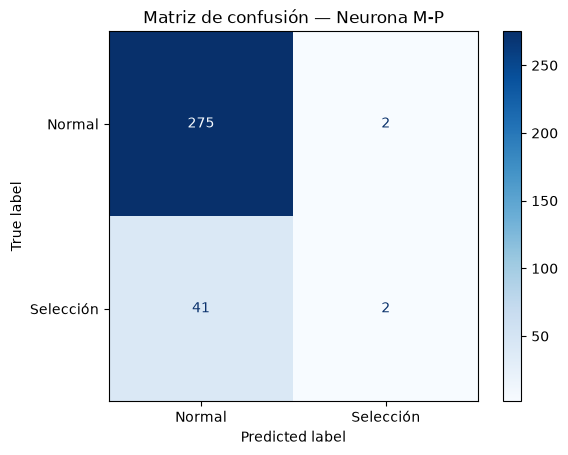

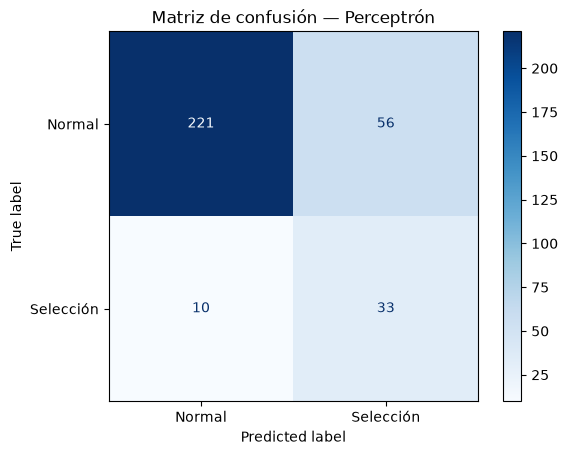

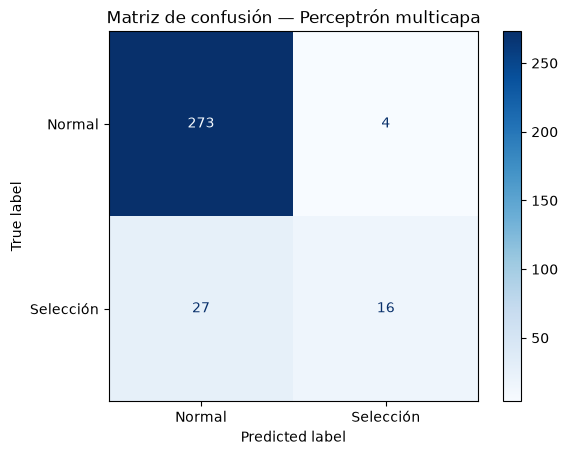

In [11]:
def evaluar(nombre, y_real, pred):
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0,1]).ravel()
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, pred),
        "Precisión Selección": precision_score(y_real, pred, zero_division=0),
        "Recall Selección": recall_score(y_real, pred, zero_division=0),
        "F1 Selección": f1_score(y_real, pred, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }

resultados = pd.DataFrame([
    evaluar("Neurona M-P", y_test, y_pred_mp),
    evaluar("Perceptrón", y_test, y_pred_perc),
    evaluar("Perceptrón multicapa", y_test, y_pred_mlp)
])
display(resultados.round(3))

for nombre, pred in [("Neurona M-P",y_pred_mp),
                     ("Perceptrón",y_pred_perc),
                     ("Perceptrón multicapa",y_pred_mlp)]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Normal","Selección"], cmap="Blues"
    )
    plt.title("Matriz de confusión — " + nombre)
    plt.show()

## 8. Traducción de resultados a lotes y euros anuales
El test representa aproximadamente el 20 % del histórico. Para estimar el impacto anual, escalamos los recuentos de test por 1.600 / número_de_test. Usamos los supuestos del cliente: 2.500 € por falso positivo y 1.200 € por falso negativo. Son estimaciones orientativas, no beneficios garantizados.

In [12]:
LOTES_ANUALES = 1600
COSTE_FP = 2500
COSTE_FN = 1200
factor = LOTES_ANUALES / len(y_test)

impacto = []
for _, fila in resultados.iterrows():
    fp_anuales = fila["FP"] * factor
    fn_anuales = fila["FN"] * factor
    coste_fp = fp_anuales * COSTE_FP
    coste_fn = fn_anuales * COSTE_FN
    impacto.append({
        "Modelo": fila["Modelo"],
        "FP estimados/año": round(fp_anuales,1),
        "FN estimados/año": round(fn_anuales,1),
        "Coste FP (€)": round(coste_fp),
        "Coste FN (€)": round(coste_fn),
        "Coste total errores (€)": round(coste_fp+coste_fn)
    })

impacto_df = pd.DataFrame(impacto).sort_values("Coste total errores (€)")
display(impacto_df)
print("Sobreprecio potencial por lote Selección: 1.200 €.")
print("Importante: el coste total de errores no descuenta costes de implantación ni mantenimiento.")

,Modelo,FP estimados/año,FN estimados/año,Coste FP (€),Coste FN (€),Coste total errores (€)
2,Perceptrón multicapa,20.0,135.0,50000,162000,212000
0,Neurona M-P,10.0,205.0,25000,246000,271000
1,Perceptrón,280.0,50.0,700000,60000,760000


Sobreprecio potencial por lote Selección: 1.200 €.
Importante: el coste total de errores no descuenta costes de implantación ni mantenimiento.


## 9. Recomendación para la bodega
La recomendación final debe basarse en la tabla económica y en la precisión de Selección. Como el falso positivo cuesta más, no se debe escoger automáticamente el modelo con más accuracy ni el de mayor recall.

**Propuesta operativa:** utilizar el modelo como filtro inicial. Los lotes con predicción clara se priorizan y los dudosos o de alto riesgo pasan al panel de cata. El sistema no sustituye a los catadores.

Antes de implantarlo:
1. Hacer un piloto con lotes reales de una nueva cosecha.
2. Mantener la cata humana para decisiones de alto impacto.
3. Revisar precisión, falsos positivos y cambios de distribución en cada cosecha.
4. Reentrenar y validar antes de poner en producción una nueva versión.

### Limitaciones
- El conjunto UCI no procede de Celler del Túria; la transferencia a esa bodega debe validarse.
- La nota del panel se convierte en una decisión binaria (≥7), perdiendo matices.
- Los costes son supuestos orientativos facilitados por el cliente.
- Los valores atípicos pueden representar casos reales y deben revisarse, no borrarse sin justificación.

## 10. Fuente de datos
Cortez, P., Cerdeira, A., Almeida, F., Matos, T. y Reis, J. (2009). *Wine Quality*. UCI Machine Learning Repository. DOI: 10.24432/C56S3T. Licencia CC BY 4.0.

**Comprobación final:** ejecutar todas las celdas, revisar las tablas y matrices, y trasladar los resultados reales del test al informe ejecutivo y a la presentación.